In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm

portfolio_df = pd.read_csv(
    "../data/processed/portfolio_returns.csv",
    index_col=0,
    parse_dates=True
)

portfolio_returns = portfolio_df["PortfolioReturn"]
portfolio_pnl = portfolio_df["PortfolioPnL"]

PORTFOLIO_VALUE = 1_000_000

portfolio_df.head()

,PortfolioReturn,PortfolioPnL
Date,,
2021-01-05,0.002310,2309.751883
2021-01-06,-0.008148,-8147.809207
2021-01-07,0.007074,7073.769144
2021-01-08,-0.002222,-2221.957662
2021-01-11,-0.006314,-6314.056374


In [2]:
historical_var_95_return = -np.percentile(
    portfolio_returns,
    5
)

historical_var_99_return = -np.percentile(
    portfolio_returns,
    1
)

historical_var_95_usd = (
    historical_var_95_return * PORTFOLIO_VALUE
)

historical_var_99_usd = (
    historical_var_99_return * PORTFOLIO_VALUE
)

print(
    "Historical VaR 95%:",
    f"${historical_var_95_usd:,.2f}"
)

print(
    "Historical VaR 99%:",
    f"${historical_var_99_usd:,.2f}"
)

Historical VaR 95%: $11,656.95
Historical VaR 99%: $17,850.98


In [3]:
mean_return = portfolio_returns.mean()
std_return = portfolio_returns.std()

z_95 = norm.ppf(0.05)
z_99 = norm.ppf(0.01)

parametric_var_95_return = -(
    mean_return
    + z_95 * std_return
)

parametric_var_99_return = -(
    mean_return
    + z_99 * std_return
)

parametric_var_95_usd = (
    parametric_var_95_return
    * PORTFOLIO_VALUE
)

parametric_var_99_usd = (
    parametric_var_99_return
    * PORTFOLIO_VALUE
)

print(
    "Parametric VaR 95%:",
    f"${parametric_var_95_usd:,.2f}"
)

print(
    "Parametric VaR 99%:",
    f"${parametric_var_99_usd:,.2f}"
)

Parametric VaR 95%: $11,476.26
Parametric VaR 99%: $16,360.45


In [4]:
asset_returns = pd.read_csv(
    "../data/processed/daily_returns.csv",
    index_col=0,
    parse_dates=True
)

asset_returns.head()

,EURUSD=X,GLD,QQQ,SPY,TLT
Date,,,,,
2021-01-05,0.000074,0.002962,0.008244,0.006887,-0.007427
2021-01-06,0.003973,-0.016241,-0.013852,0.005978,-0.020528
2021-01-07,0.003320,-0.002335,0.024192,0.014857,-0.008815
2021-01-08,-0.005645,-0.034210,0.012858,0.005698,-0.003227
2021-01-11,-0.006946,-0.001961,-0.014450,-0.006741,-0.001652


In [5]:
weights = pd.Series({
    "SPY": 0.30,
    "QQQ": 0.20,
    "TLT": 0.25,
    "GLD": 0.15,
    "EURUSD=X": 0.10
})

weights = weights.reindex(
    asset_returns.columns
)

weights

EURUSD=X    0.10
GLD         0.15
QQQ         0.20
SPY         0.30
TLT         0.25
dtype: float64

In [6]:
mean_vector = asset_returns.mean()
cov_matrix = asset_returns.cov()

In [7]:
np.random.seed(42)

n_simulations = 100_000

simulated_asset_returns = (
    np.random.multivariate_normal(
        mean=mean_vector,
        cov=cov_matrix,
        size=n_simulations
    )
)

In [8]:
simulated_asset_returns.shape

(100000, 5)

In [9]:
simulated_portfolio_returns = (
    simulated_asset_returns
    @ weights.values
)

In [10]:
simulated_portfolio_pnl = (
    simulated_portfolio_returns
    * PORTFOLIO_VALUE
)

In [11]:
monte_carlo_var_95_usd = -np.percentile(
    simulated_portfolio_pnl,
    5
)

monte_carlo_var_99_usd = -np.percentile(
    simulated_portfolio_pnl,
    1
)

print(
    "Monte Carlo VaR 95%:",
    f"${monte_carlo_var_95_usd:,.2f}"
)

print(
    "Monte Carlo VaR 99%:",
    f"${monte_carlo_var_99_usd:,.2f}"
)

Monte Carlo VaR 95%: $11,505.02
Monte Carlo VaR 99%: $16,406.90


In [12]:
var_comparison = pd.DataFrame({
    "Method": [
        "Historical",
        "Parametric",
        "Monte Carlo"
    ],

    "VaR_95_USD": [
        historical_var_95_usd,
        parametric_var_95_usd,
        monte_carlo_var_95_usd
    ],

    "VaR_99_USD": [
        historical_var_99_usd,
        parametric_var_99_usd,
        monte_carlo_var_99_usd
    ]
})

var_comparison

,Method,VaR_95_USD,VaR_99_USD
0,Historical,11656.950277,17850.975906
1,Parametric,11476.261456,16360.450008
2,Monte Carlo,11505.024202,16406.898212


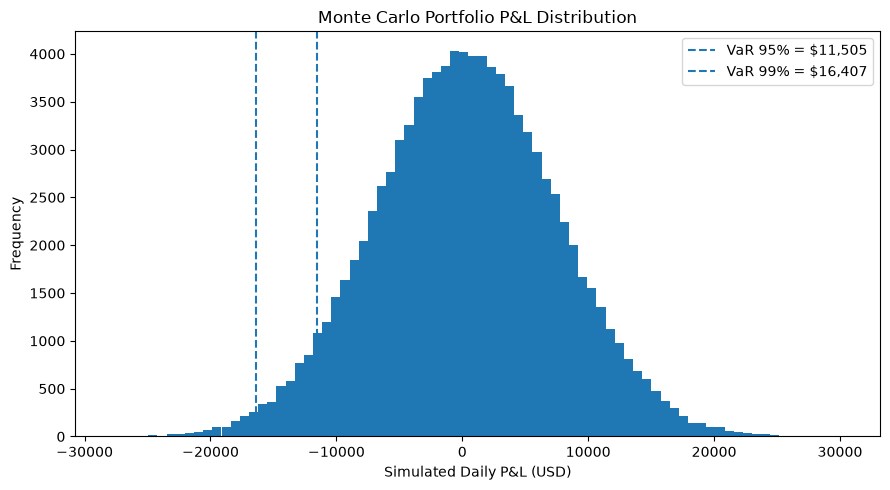

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    simulated_portfolio_pnl,
    bins=80
)

plt.axvline(
    -monte_carlo_var_95_usd,
    linestyle="--",
    label=f"VaR 95% = ${monte_carlo_var_95_usd:,.0f}"
)

plt.axvline(
    -monte_carlo_var_99_usd,
    linestyle="--",
    label=f"VaR 99% = ${monte_carlo_var_99_usd:,.0f}"
)

plt.xlabel("Simulated Daily P&L (USD)")
plt.ylabel("Frequency")

plt.title(
    "Monte Carlo Portfolio P&L Distribution"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "../reports/figures/monte_carlo_var.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Value at Risk Models

Three approaches were implemented to estimate one-day portfolio Value at Risk:

1. Historical Simulation
2. Parametric VaR
3. Monte Carlo Simulation

Historical VaR uses the empirical distribution of observed portfolio returns.

Parametric VaR assumes approximately normally distributed portfolio returns and estimates risk using the portfolio mean and volatility.

Monte Carlo VaR generates simulated joint asset returns using the historical mean vector and covariance matrix, preserving estimated cross-asset correlations.

VaR should not be interpreted as the maximum possible loss. It represents a loss threshold associated with a specified confidence level under the assumptions of each methodology.